<a href="https://colab.research.google.com/github/anupbagale/Neural_Network_lab/blob/main/notebooks/07_bidirectional_associative_memory.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lesson 7: Bidirectional Associative Memory

Lesson 7 of 8, about 35 minutes.

After this lesson you should be able to:

1. Store pattern pairs in a bidirectional associative memory (BAM) with the outer-product rule.
2. Recall a pattern from its partner in either direction.
3. Use the energy function to explain why recall always stops.
4. Measure how many pairs a BAM can hold before recall breaks down.

You will need: lesson 3 (Hebbian learning) and outer products of vectors.

In [1]:
# Setup (works locally and on Google Colab)
try:
    import nnlab
except ImportError:  # not installed yet, e.g. on Colab
    %pip install -q "git+https://github.com/anupbagale/Neural_Network_lab"
    import nnlab

import numpy as np
import matplotlib.pyplot as plt
from nnlab.style import apply_style, PALETTE

apply_style()
np.set_printoptions(precision=3, suppress=True)

## Associative memory

People remember by association: a face reminds you of a name. Kosko's bidirectional associative
memory (BAM, 1988) is a two-layer network that does something similar with bipolar patterns. It
stores pairs $(\mathbf{a}_k, \mathbf{b}_k)$ with $\mathbf{a}_k \in \{-1,1\}^n$ and
$\mathbf{b}_k \in \{-1,1\}^p$ in a single weight matrix, built with Hebb's rule from lesson 3:

$$
W = \sum_{k} \mathbf{a}_k^\top \mathbf{b}_k \qquad (n \times p).
$$

To recall, activity is passed back and forth between the two layers until nothing changes:

$$
\mathbf{b} = \operatorname{sgn}(\mathbf{a}\,W), \qquad \mathbf{a} = \operatorname{sgn}(\mathbf{b}\,W^\top).
$$

In [2]:
from nnlab.bam import BAM

A = np.array([[ 1,  1, -1, -1,  1],
              [-1,  1,  1, -1, -1],
              [ 1,  1, -1,  1, -1]])
B = np.array([[-1, -1,  1,  1, -1,  1, -1],
              [-1, -1, -1, -1, -1, -1, -1],
              [ 1,  1,  1, -1, -1, -1, -1]])

bam = BAM.from_pairs(A, B)
print("W =\n", bam.W.astype(int))

W =
 [[ 1  1  3  1 -1  1 -1]
 [-1 -1  1 -1 -3 -1 -3]
 [-1 -1 -3 -1  1 -1  1]
 [ 3  3  1 -1  1 -1  1]
 [-1 -1  1  3  1  3  1]]


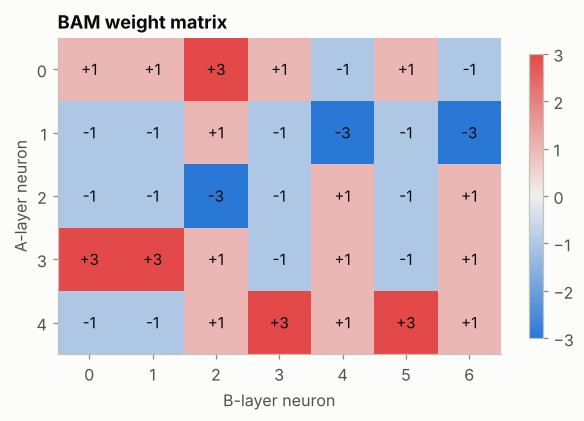

In [3]:
fig, ax = plt.subplots(figsize=(6.5, 4.2))
lim = np.abs(bam.W).max()
im = ax.imshow(bam.W, cmap="nnlab_div", vmin=-lim, vmax=lim)
for (i, j), v in np.ndenumerate(bam.W):
    ax.text(j, i, f"{v:+.0f}", ha="center", va="center", fontsize=10, color="#0b0b0b")
ax.set(xticks=range(B.shape[1]), yticks=range(A.shape[1]),
       xlabel="B-layer neuron", ylabel="A-layer neuron", title="BAM weight matrix")
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8)
plt.show()

## Recall in both directions

In [4]:
for k, (a, b) in enumerate(zip(A, B), 1):
    b_hat = bam.forward(a)
    a_hat = bam.backward(b)
    print(f"pair {k}:  A to B correct: {np.array_equal(b_hat, b)}   B to A correct: {np.array_equal(a_hat, a)}")

pair 1:  A to B correct: True   B to A correct: True
pair 2:  A to B correct: True   B to A correct: True
pair 3:  A to B correct: True   B to A correct: True


## Recall from a noisy cue

What makes an associative memory useful is that a damaged cue can still bring back the whole
stored pair. Kosko showed that the energy

$$E(\mathbf{a}, \mathbf{b}) = -\,\mathbf{a}\,W\,\mathbf{b}^\top$$

never increases during recall and has a lower bound, so the back-and-forth has to stop at a stable pair.

In [5]:
cue = B[0].copy()
cue[0] *= -1                      # flip the first bit of b1
trace = bam.recall_from_b(cue)

print("noisy cue b:", cue)
print("recalled b: ", trace.b.astype(int), " correct:", np.array_equal(trace.b, B[0]))
print("recalled a: ", trace.a.astype(int), " correct:", np.array_equal(trace.a, A[0]))
print("energies:   ", trace.energies)

noisy cue b: [ 1 -1  1  1 -1  1 -1]
recalled b:  [-1 -1  1  1 -1  1 -1]  correct: True
recalled a:  [ 1  1 -1 -1  1]  correct: True
energies:    [-33.0, -33.0]


Does that always work? The next cell tries every possible one-bit error, on both sides, for every
stored pair. "ok" means the original pair came back and "-" means it did not.

In [6]:
def robustness(cues, recall):
    rows = []
    for k in range(len(A)):
        hits = []
        for i in range(cues.shape[1]):
            c = cues[k].copy(); c[i] *= -1
            t = recall(c)
            hits.append(np.array_equal(t.a, A[k]) and np.array_equal(t.b, B[k]))
        rows.append(hits)
    return np.array(rows)

for side, cues, recall in [("A", A, bam.recall), ("B", B, bam.recall_from_b)]:
    table = robustness(cues, recall)
    print(f"one-bit errors in {side} ({cues.shape[1]} neurons): {table.sum()} of {table.size} corrected")
    for k, row in enumerate(table, 1):
        print(f"    pair {k}: " + " ".join("ok" if h else " -" for h in row))

one-bit errors in A (5 neurons): 6 of 15 corrected
    pair 1: ok  - ok  -  -
    pair 2: ok  - ok  -  -
    pair 3: ok  - ok  -  -
one-bit errors in B (7 neurons): 18 of 21 corrected
    pair 1: ok ok  - ok ok ok ok
    pair 2: ok ok  - ok ok ok ok
    pair 3: ok ok  - ok ok ok ok


Errors on the B side, which has 7 neurons, are nearly always corrected. Many errors on the A side,
which has only 5, are not. In those cases recall settles on a different stable state, either another
pair or a spurious memory that was never stored. Recall always stops somewhere, as the energy
argument says, but not always at the pair we wanted. With so few neurons, three pairs already
crowd the memory.

## Capacity

The first version of this lab also stored a fourth, randomly generated pair (using
`np.random.seed(2)`) and found that it was not recalled correctly. That is not a bug. Associative
memories can only hold a limited number of pairs. Here is the same experiment again:

In [7]:
np.random.seed(2)                                   # same random pair as the original notebook
a4 = np.random.randint(-1, 2, 5); a4[a4 < 0.5] = -1
b4 = np.random.randint(-1, 2, 7); b4[b4 < 0.5] = -1

bam4 = BAM.from_pairs(np.vstack([A, a4]), np.vstack([B, b4]))
for k, (a, b) in enumerate(zip(np.vstack([A, a4]), np.vstack([B, b4])), 1):
    errors = int(np.sum(bam4.backward(bam4.forward(a)) != a))
    print(f"pair {k}: {errors} wrong bit(s) after A to B to A")

pair 1: 0 wrong bit(s) after A to B to A
pair 2: 0 wrong bit(s) after A to B to A
pair 3: 0 wrong bit(s) after A to B to A
pair 4: 1 wrong bit(s) after A to B to A


Each stored pair adds interference (crosstalk) to $W$, and with only 5 neurons on the A side the
memory fills up quickly. The capacity of a BAM is often quoted as at most $\min(n, p)$ pairs
(Kosko, 1988), and for random patterns it is usually lower. The next cell measures it for
$n = p = 40$.

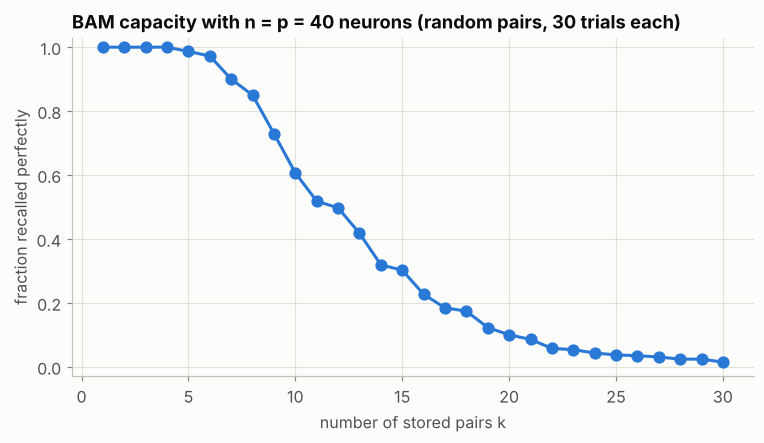

In [8]:
from nnlab.bam import random_bipolar_pairs

rng = np.random.default_rng(42)
n = p = 40
ks = range(1, 31)
trials = 30
perfect = []
for k in ks:
    ok = 0
    for _ in range(trials):
        As, Bs = random_bipolar_pairs(k, n, p, rng)
        mem = BAM.from_pairs(As, Bs)
        ok += np.mean([np.array_equal(mem.forward(a), b) for a, b in zip(As, Bs)])
    perfect.append(ok / trials)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(list(ks), perfect, marker="o", color=PALETTE[0])
ax.set(xlabel="number of stored pairs k", ylabel="fraction recalled perfectly",
       title=f"BAM capacity with n = p = {n} neurons (random pairs, {trials} trials each)", ylim=(-0.03, 1.03))
plt.show()

## Exercises

1. Flip 2 bits of `A[0]` instead of 1. Does recall still work? Try it for every pair.
2. Repeat the capacity experiment with $n = p = 80$. Roughly how does capacity grow with the
   number of neurons?
3. Store a pair together with its complement $(-\mathbf{a}, -\mathbf{b})$. What happens to $W$?

**Answer to exercise 3**

<details><summary>Answer</summary>

$(-\mathbf{a})^\top(-\mathbf{b}) = \mathbf{a}^\top\mathbf{b}$, so storing the complement just adds the same term again. It also means a BAM stores the complement of every pair automatically, which is a well-known source of spurious memories.

</details>

## Summary

- A BAM stores pairs of bipolar patterns in one matrix using Hebb's outer-product rule.
- Recall goes back and forth between the layers until it reaches a stable pair. The energy never increases.
- A noisy cue can often bring back the full stored pair, but not always.
- Capacity is limited, because stored pairs interfere with each other.

Next: [Lesson 8, Fuzzy Sets](08_fuzzy_sets.ipynb)

### References

- Kosko, B. (1988). Bidirectional associative memories. *IEEE Transactions on Systems, Man, and Cybernetics*, 18(1), 49–60.
- Hebb, D. O. (1949). *The Organization of Behavior: A Neuropsychological Theory*. Wiley.
- Zurada, J. M. (1992). *Introduction to Artificial Neural Systems*. West Publishing Company.